# ICS 3202 Artificial Intelligence: Semester Project
# Base model: a Naive Bayes transaction categoriser

This notebook builds the base model for Akiba, a personal-finance app with an AI advisor that helps
students track their spending. The model reads an M-Pesa transaction (a short description and an
amount) and suggests one of nine expense categories.

What is covered:

- Part A: the ML approach and the algorithms that fit this problem
- Part B: cleaning the data, from the raw file to the modelling dataset
- Part C: exploratory data analysis, with six observations
- Part D: the base model and how it is evaluated
- Part E: comparison models built through the same process
- Part F: conclusions and next steps

Every number, table and figure below is computed when the notebook runs. Repository: `SemProject_MLEngine`.

---
# From Deliverable 1 to Deliverable 2

Deliverable 1 (`Expenses_Exploration.ipynb`) explored `Expenses_clean.csv`, the Kaggle *Financial
Transactions Dataset (Expenses & Income)*: 938 rows of personal spending in BYN, with six columns
(`date_time`, `category`, `account`, `amount`, `currency`, `tags`).

That exploration showed the dataset has no description or merchant text column. Akiba's categoriser has
to map an M-Pesa description to a category, and rows that only carry a date, an account, an amount and an
already-filled category give the model nothing to learn from. Finding out that a dataset cannot support
the task is a valid result of exploration, not a failure. It is exactly the question exploration is for.

There is a second, separate reason. The expenses file has 14 categories (Cafe, Clothes, Fines, Leisure,
Loan given, Public transport and others) while Akiba has 9, so even with a text column the labels would
not line up without a mapping that drops or merges categories. `Income_clean.csv` (349 rows,
7 categories) is committed next to it in `data/`. Income is not classified in v1 of the categoriser.

With no real labelled data (the app has no users yet), the project builds its own training set from a
hand-made list of Kenyan merchants:

```
lexicon.json  →  generate.py  →  data/train.csv
```

`data/train.csv` is the dataset modelled in this notebook. The Kaggle data plays no part in training the
shipped model. It is still useful for tasks that need no description text, such as clustering spending
behaviour or forecasting monthly spend per category, which are candidates for a later deliverable.

---
# How this notebook follows CRISP-DM

The course frames data-mining projects with CRISP-DM, which has six phases. This notebook keeps its own
part structure, and each part names the phase it belongs to.

| CRISP-DM phase | Where it happens |
|---|---|
| Business understanding | Part A: what the app must produce, and the task type |
| Data understanding | The first sections of Part B, plus Part C (EDA) |
| Data preparation | Part B: the seven cleaning steps |
| Modelling | Part D: the base model |
| Evaluation | Part D's checks and the Part E model comparison |
| Deployment | The export to `out/model.json`, which the app's TypeScript server loads |

The notes call business understanding the most critical task, and data preparation is usually the
longest phase. That holds here too: Part B is the longest part of the notebook.

---
# Part A: The ML approach
*CRISP-DM phase: business understanding*

## What the app has to produce

A line from a user's M-Pesa statement arrives as free text plus a number:

```
"merchant payment to naivas westlands"   KES 1,240
```

The app has to return one of nine expense categories (Food, Rent, Transport, Academic, Airtime & Data,
Entertainment, Health, Personal Care, Other) together with a confidence score. The app uses the score to
decide whether to apply the label automatically or ask the user to confirm it.

There is also a hard constraint: the model ships as a single JSON file and runs in pure TypeScript inside
the app's Express server. There is no Python service and no external API call.

## The two datasets

| | Deliverable 1 dataset | Modelling dataset (this notebook) |
|---|---|---|
| File | `Expenses_clean.csv` (Kaggle) | `data/train.csv` |
| Origin | Exported from a finance-tracking app | Generated by `generate.py` from `lexicon.json` |
| Rows | 938 | 5,587 |
| Columns | `date_time`, `category`, `account`, `amount`, `currency`, `tags` | `description`, `amount`, `category`, `keyword` |
| Currency | BYN (Belarusian rouble) | KES |
| Has a text description? | No | Yes |

Only the second one can train this model, for the reasons above. The Kaggle data is also in BYN and
reflects Belarusian spending, which would not transfer to Kenyan M-Pesa descriptions anyway.

## Task type

Every training row already has its category, so this is **supervised learning**. The target is one of
nine discrete labels with exactly one label per row, so it is **multi-class classification**. The main
input is a few words of free text, which makes it a text classification problem.

Unsupervised methods such as K-Means clustering are ruled out because the labels already exist and must
match the app's fixed nine categories. Regression is ruled out because the target is a category, not a
number.

## Candidate algorithms

All of these come from the course's ML cheat sheet and the Theories of Machine Learning lecture.

| Algorithm | Fit for this problem |
|---|---|
| **Multinomial Naive Bayes** | Built for word counts and trains in milliseconds. The whole model is a table of log-probabilities, which is easy to port to TypeScript. Chosen as the base model. |
| Logistic Regression | A strong linear classifier for text, with regularisation built in |
| Decision Tree | Easy to read, but tends to over-fit when there are thousands of sparse features |
| K-Nearest Neighbours | Labels a row by its most similar training rows, so it depends on what "similar" means for text |
| Random Forest | Averages many trees, which reduces the over-fitting of a single tree |
| Gradient Boosting | Builds trees one after another, each correcting the mistakes of the last |

Naive Bayes is the base model because of the deployment constraint: predicting a category is one sum of
log-probabilities per class, which takes a few lines of TypeScript. Part E checks whether that choice
costs accuracy.

---
# Part B: Cleaning the data
*CRISP-DM phases: data understanding, then data preparation*

This part first looks at where the data comes from and what is in the raw file. It then works through
the seven data cleaning steps from the course notes, in order, and says for each one what was done or
why the step did not apply.

The first cell loads the libraries and finds `data/train.csv`.

In [1]:
import json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-",
    "figure.facecolor": "white", "axes.facecolor": "white",
})

NAVY, BLUE, TEAL, AMBER, RED, GREY = "#1C3F63", "#2A6FA8", "#127A73", "#C8781A", "#C0564B", "#637586"
PALETTE = [BLUE, TEAL, AMBER, NAVY, RED, "#7E57A2", "#4C9A6A", "#B5852C", GREY]
HEAT = LinearSegmentedColormap.from_list("heat", ["#FFFFFF", "#CFE0EE", "#2A6FA8", "#1C3F63"])

def hboxplot(ax, data, tick_labels, **kw):
    """Horizontal boxplot that works across matplotlib versions.

    matplotlib >= 3.9 renamed `labels` to `tick_labels`; >= 3.10 replaced
    `vert=False` with `orientation="horizontal"`. Try the modern spelling,
    fall back to the legacy one.
    """
    try:
        bp = ax.boxplot(data, orientation="horizontal", **kw)
    except TypeError:
        bp = ax.boxplot(data, vert=False, **kw)
    ax.set_yticks(range(1, len(tick_labels) + 1))
    ax.set_yticklabels(tick_labels)
    return bp

# Locate data/train.csv whether the notebook runs from notebooks/, the repo root, or Colab
CANDIDATES = [Path("data/train.csv"), Path("../data/train.csv"), Path("train.csv")]
TRAIN_CSV = next((p for p in CANDIDATES if p.exists()), None)
if TRAIN_CSV is None:
    raise FileNotFoundError(
        "data/train.csv not found. Run `python scripts/generate.py` at the repo root first, "
        "or upload data/train.csv if running in Colab."
    )
# Paths are reported relative to the repo root so no machine-specific directory ends up in the output
REPO_ROOT = TRAIN_CSV.resolve().parents[1] if TRAIN_CSV.parent.name == "data" else TRAIN_CSV.resolve().parent
print("Loaded from:", TRAIN_CSV.resolve().relative_to(REPO_ROOT).as_posix())

Loaded from: data/train.csv


## Where the data comes from

There are no users yet, so there is no labelled history to learn from. `generate.py` builds a training
set from `lexicon.json`, a hand-made list of 457 Kenyan merchants and keywords spread over the nine
categories. For each keyword it writes 11 to 14 rows, each an M-Pesa-style sentence such as
`pay bill to {keyword}` or `merchant payment to {keyword} {place}`, with an amount drawn at random from a
range set for that category.

The same twelve sentence templates are used for every category, so words like "pay bill" or
"lipa na mpesa" should say nothing about the category. Only the keyword should. Step 2 checks this
instead of taking it on trust.

Some cleaning already happens inside the generator, before the CSV exists. It stops if a category has no
keywords or no amount range, it rejects a keyword listed under two different categories, and it uses a
fixed random seed (42) so the file can be rebuilt exactly.

The cell below loads the raw file and shows its shape, column types and a sample.

In [2]:
raw = pd.read_csv(TRAIN_CSV)

print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns\n")
print("Datatypes:"); print(raw.dtypes.to_string())
# `keyword` records which lexicon entry produced the row; it is not used as a feature
raw.head(8)

Shape: 5,587 rows x 4 columns

Datatypes:
description      str
amount         int64
category         str
keyword          str


,description,amount,category,keyword
0,faiba cbd,340,Airtime & Data,faiba
1,buy goods grocery,115,Food,grocery
2,customer transfer to pharmacy,2612,Health,pharmacy
3,merchant payment to cash thika road,65,Other,cash
4,pay bill online to pizza,171,Food,pizza
5,pay bill online to faras,611,Transport,faras
6,gym branch westlands,2110,Personal Care,gym
7,customer transfer to m shwari,59,Other,m shwari


## Step 1: Scrub for duplicates

Exact duplicate rows would give some transactions extra weight for no reason. The cell below counts exact
duplicates (same description, amount and category), repeated description strings, and repeated
descriptions that carry two different categories, which would be contradictory labels.

There are no exact duplicates. There are 202 repeated description strings, but none of them has two
different categories, so they are consistent repeats (the same merchant and template at a different
amount) rather than label noise. They are kept, because dropping them would change the class balance.

The bigger kind of duplication is near-duplicates. Every row comes from one of 457 keywords, so each
merchant appears 11 to 14 times with only the template and amount changing. These rows are how the model
learns each merchant, so they stay, but they matter for evaluation (see the limitation note in Part D).

In [3]:
# An exact duplicate has the same description, amount and category
exact_dupes = int(raw.duplicated(["description", "amount", "category"]).sum())
repeated_text = int(raw.description.duplicated().sum())
# A repeated description with two different categories would be contradictory label noise
contradictory = int((raw.groupby("description").category.nunique() > 1).sum())

print(f"Exact duplicate rows:                     {exact_dupes}")
print(f"Repeated description strings:             {repeated_text}")
print(f"Repeated descriptions with two categories: {contradictory}\n")

kw_stats = (raw.groupby("category")
              .agg(rows=("category", "size"), keywords=("keyword", "nunique"))
              .assign(rows_per_keyword=lambda t: (t.rows / t.keywords).round(1))
              .sort_values("keywords"))
display(kw_stats)
print(f"{raw.keyword.nunique()} distinct merchant keywords behind {len(raw):,} rows")

Exact duplicate rows:                     0
Repeated description strings:             202
Repeated descriptions with two categories: 0



,rows,keywords,rows_per_keyword
category,,,
Airtime & Data,602,43,14.0
Rent,630,45,14.0
Health,611,47,13.0
Personal Care,637,49,13.0
Other,612,51,12.0
Entertainment,636,53,12.0
Food,616,56,11.0
Academic,616,56,11.0
Transport,627,57,11.0


457 distinct merchant keywords behind 5,587 rows


## Step 2: Scrub for irrelevant data

Real M-Pesa descriptions contain receipt codes, phone numbers, digits and punctuation. None of it says
anything about the category, and because each code is unique the model could never learn from it anyway.
`clean()` in `scripts/features.py` replaces every character that is not a letter or a space with a space,
then collapses repeated spaces. The demo below runs it on five made-up raw descriptions.

The same steps run in the app's TypeScript code (`text.ts`), so the notebook imports `features.py` instead
of copying it. If the two ever differed, the app would quietly give wrong categories.

In [4]:
# Mirrors features.py exactly. Imported if available so the notebook cannot drift from the shipped code.
import sys
sys.path.insert(0, str(REPO_ROOT / "scripts"))   # scripts/ sits beside data/, from notebooks/ or the repo root
try:
    import features
    from features import clean, amount_bucket, to_document, vectorizer_kwargs
    print(f"Using {Path(features.__file__).resolve().relative_to(REPO_ROOT).as_posix()} "
          "from the repository (single source of truth).")
except ImportError:
    print("features.py not importable, so using the inline equivalent.")
    AMOUNT_BUCKETS = [(0,100,"amt_xs"), (100,500,"amt_s"), (500,2000,"amt_m"),
                      (2000,10000,"amt_l"), (10000,None,"amt_xl")]
    _NON_ALPHA, _SPACES = re.compile(r"[^a-z\s]+"), re.compile(r"\s+")

    def clean(text):
        text = "" if text is None else str(text)
        return _SPACES.sub(" ", _NON_ALPHA.sub(" ", text.lower())).strip()

    def amount_bucket(amount):
        v = abs(float(amount or 0))
        for low, high, tok in AMOUNT_BUCKETS:
            if high is None or v < high:
                return tok
        return AMOUNT_BUCKETS[-1][2]

    def to_document(description, amount):
        c = clean(description)
        b = amount_bucket(amount)
        return f"{c} {b}" if c else b

    def vectorizer_kwargs():
        return {"lowercase": False, "token_pattern": r"\S+", "ngram_range": (1, 2)}

demo = pd.DataFrame({
    "raw_description": ["Pay Bill to NAIVAS #4471", "ARTCAFFE LTD, Westlands",
                        "merchant payment to JAVA HOUSE", "UBER*TRIP 0712345678", "KPLC PREPAID TOKEN"],
    "amount": [1240, 85, 650, 320, 15000],
})
demo["after_clean()"]  = demo.raw_description.map(clean)
demo["amount_bucket()"] = demo.amount.map(amount_bucket)
demo["final_document"] = [to_document(d, a) for d, a in zip(demo.raw_description, demo.amount)]
display(demo)

print("The receipt code '#4471', the phone number and the '*' are all removed,")
print("and the amount comes back as a single token at the end (Step 7).")

Using scripts/features.py from the repository (single source of truth).


,raw_description,amount,after_clean(),amount_bucket(),final_document
0,Pay Bill to NAIVAS #4471,1240,pay bill to naivas,amt_m,pay bill to naivas amt_m
1,"ARTCAFFE LTD, Westlands",85,artcaffe ltd westlands,amt_xs,artcaffe ltd westlands amt_xs
2,merchant payment to JAVA HOUSE,650,merchant payment to java house,amt_m,merchant payment to java house amt_m
3,UBER*TRIP 0712345678,320,uber trip,amt_s,uber trip amt_s
4,KPLC PREPAID TOKEN,15000,kplc prepaid token,amt_xl,kplc prepaid token amt_xl


The receipt code '#4471', the phone number and the '*' are all removed,
and the amount comes back as a single token at the end (Step 7).


The template words ("pay", "bill", "merchant", "lipa na mpesa" and so on) are also irrelevant to the
category, but they are kept on purpose because real statements contain them too. The check below makes
sure they really carry no category signal. If a word were spread perfectly evenly, each category would
hold 1/9 (0.111) of the rows that contain it.

In [5]:
# The generator applies all 12 templates to all 9 categories, so template words should be
# spread about evenly across categories. An even share is 1/9 = 0.111.
TEMPLATE_WORDS = ["pay","bill","buy","goods","merchant","payment","customer",
                  "transfer","ltd","limited","lipa","na","mpesa","branch","online"]
UNIFORM = 1 / raw.category.nunique()

rows = []
for tok in TEMPLATE_WORDS:
    mask = raw.description.str.split().map(lambda s: tok in s)
    if mask.sum():
        share = raw.loc[mask, "category"].value_counts(normalize=True)
        rows.append({"token": tok, "rows": int(mask.sum()),
                     "max_category_share": round(share.max(), 3),
                     "most_skewed_toward": share.idxmax()})
neutrality = pd.DataFrame(rows).sort_values("max_category_share", ascending=False)
display(neutrality)

worst = neutrality.max_category_share.max()
print(f"An even share would be {UNIFORM:.3f}. The most concentrated template word reaches {worst:.3f}.")
print("So no template word is a shortcut to a category: the model cannot score well by learning the templates.")

,token,rows,max_category_share,most_skewed_toward
1,bill,986,0.132,Airtime & Data
12,mpesa,474,0.131,Other
2,buy,471,0.125,Airtime & Data
13,branch,472,0.125,Rent
9,limited,469,0.122,Personal Care
14,online,470,0.119,Rent
3,goods,458,0.118,Transport
7,transfer,460,0.117,Personal Care
6,customer,460,0.117,Personal Care
4,merchant,933,0.117,Personal Care


An even share would be 0.111. The most concentrated template word reaches 0.132.
So no template word is a shortcut to a category: the model cannot score well by learning the templates.


## Step 3: Scrub for incorrect data

The values most likely to be wrong are the amounts: a zero, a negative number, or an amount that makes no
sense for its category. The generator draws every amount from a range set for its category in
`generate.py` (for example KES 300 to 45,000 for Rent), so the amounts are positive and in range by
construction. The generator does not check this afterwards, so the cell below does, using the
generator's own ranges.

In [6]:
# Use the generator's own ranges so this check cannot drift from how the data was made
from generate import AMOUNT_RANGES

ranges = raw.groupby("category").amount.agg(["min", "max"])
ranges["allowed_min"] = [AMOUNT_RANGES[c][0] for c in ranges.index]
ranges["allowed_max"] = [AMOUNT_RANGES[c][1] for c in ranges.index]
ranges["inside_range"] = (ranges["min"] >= ranges.allowed_min) & (ranges["max"] <= ranges.allowed_max)
display(ranges)

print(f"Non-positive amounts: {int((raw.amount <= 0).sum())}")
print(f"Categories with an amount outside their allowed range: {int((~ranges.inside_range).sum())}")

,min,max,allowed_min,allowed_max,inside_range
category,,,,,
Academic,20,58090,20,60000,True
Airtime & Data,10,2987,10,3000,True
Entertainment,100,4989,100,5000,True
Food,50,4991,50,5000,True
Health,100,9912,100,10000,True
Other,50,9831,50,10000,True
Personal Care,100,4979,100,5000,True
Rent,307,44911,300,45000,True
Transport,50,2964,50,3000,True


Non-positive amounts: 0
Categories with an amount outside their allowed range: 0


## Step 4: Fix structural errors

Structural errors are things like "NAIVAS", "Naivas" and "naivas " being counted as three different
merchants. Two things prevent this. `clean()` lowercases every description and trims extra spaces, so case
and spacing can never split one merchant into several words. And the generator lowercases each keyword and
stops if the same keyword is listed under two different categories.

In this generated file the check below finds nothing left to fix, because the lexicon is already
lowercase and the category names are spelled consistently. Real statements mix capitals and lowercase
(as in the Step 2 demo), so this step matters as soon as real data arrives.

In [7]:
# Capital letters, or leading, trailing or double spaces, would split one merchant into several words
has_capitals = raw.description.str.contains("[A-Z]")
bad_spacing = (raw.description != raw.description.str.strip()) | raw.description.str.contains("  ")

print(f"Descriptions with capital letters:             {int(has_capitals.sum())}")
print(f"Descriptions with leading/trailing/double spaces: {int(bad_spacing.sum())}")
print(f"Distinct category names ({raw.category.nunique()}): {', '.join(sorted(raw.category.unique()))}")

Descriptions with capital letters:             0
Descriptions with leading/trailing/double spaces: 0
Distinct category names (9): Academic, Airtime & Data, Entertainment, Food, Health, Other, Personal Care, Rent, Transport


## Step 5: Handling missing data

The notes describe three kinds of missing data (missing completely at random, missing at random, and
missing not at random) and the usual tools: `isnull()` to find it, then `dropna()` or `fillna()` to deal
with it. Here the count below is zero in every column. That is expected, because the generator writes
every field of every row, so a generated dataset cannot contain nulls.

Real M-Pesa data would. A statement line can have an empty description, and hand-labelled rows can be
left without a category, which is why `scripts/train.py` drops rows with no category when it loads data.

In [8]:
missing = raw.isnull().sum()
print("Missing values per column:")
print(missing.to_string())
print(f"\nTotal missing values: {int(missing.sum())}")
print(f"Blank or whitespace-only descriptions: {int(raw.description.astype(str).str.strip().eq('').sum())}")

Missing values per column:
description    0
amount         0
category       0
keyword        0

Total missing values: 0
Blank or whitespace-only descriptions: 0


## Step 6: Treating outliers

Outliers are usually found with a boxplot or scatterplot, then dropped or replaced with the mean or
median. Here there are no true outliers by construction: every amount is drawn from a fixed range for its
category, and Step 3 showed that none fall outside it.

The boxplot in Figure 2a (Part C) does show points beyond the whiskers. The cell below counts them with
the same rule a boxplot uses (more than 1.5 times the interquartile range beyond the box). These points
are the expensive end of each range, such as a large rent payment, not mistakes, so nothing is dropped.

In [9]:
# The same rule a boxplot uses for its whiskers: more than 1.5 x IQR beyond the box
def boxplot_outliers(amounts):
    q1, q3 = amounts.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((amounts < q1 - 1.5 * iqr) | (amounts > q3 + 1.5 * iqr)).sum())

flagged = raw.groupby("category").amount.apply(boxplot_outliers)
print("Amounts beyond the boxplot whiskers, per category:")
print(flagged.to_string())
print(f"\nTotal: {flagged.sum()} of {len(raw):,} rows. "
      f"All inside their category's allowed range (Step 3): {bool(ranges.inside_range.all())}")

Amounts beyond the boxplot whiskers, per category:
category
Academic          80
Airtime & Data    59
Entertainment     21
Food              39
Health            31
Other             59
Personal Care     35
Rent              60
Transport         27

Total: 411 of 5,587 rows. All inside their category's allowed range (Step 3): True


## Step 7: Standardise and normalise

The text was already put into a common format by `clean()` in Step 2 (lowercase, letters only, single
spaces). That is the standardisation step.

The amount needs more thought. Multinomial Naive Bayes works on counts, so feeding it `1240` would mean
"this word appeared 1,240 times". Scaling it with a Standard Scaler or MinMax Scaler would not fix that.
Instead, the amount is converted into one of five bands, and the band is added to the text as one extra
word. This is the normalisation step:

| Token | Range (KES) | Typical student transaction |
|---|---|---|
| `amt_xs` | under 100 | matatu fare, airtime top-up |
| `amt_s` | 100 to 499 | lunch, data bundle |
| `amt_m` | 500 to 1,999 | weekly groceries |
| `amt_l` | 2,000 to 9,999 | utility bill, clinic visit |
| `amt_xl` | 10,000 and above | rent, semester fees |

Bands are also less sensitive to small price changes than a raw number. The cell below builds the final
document for every row: the cleaned text plus its amount token.

In [10]:
df = raw.copy()
# The final model input: cleaned text with the amount band appended as one extra word
df["doc"]      = [to_document(d, a) for d, a in zip(df.description, df.amount)]
df["bucket"]   = df.amount.map(amount_bucket)
df["n_tokens"] = df.description.str.split().str.len()

ORDER = ["amt_xs", "amt_s", "amt_m", "amt_l", "amt_xl"]
print("Bucket distribution across the whole dataset:")
print(df.bucket.value_counts().reindex(ORDER).to_frame("rows").assign(
    pct=lambda t: (t.rows / len(df) * 100).round(1)).to_string())
print("\nExample documents:")
print(df[["description", "amount", "doc"]].head(4).to_string(index=False))

Bucket distribution across the whole dataset:
        rows   pct
bucket            
amt_xs   647  11.6
amt_s   1769  31.7
amt_m   1593  28.5
amt_l   1254  22.4
amt_xl   324   5.8

Example documents:
                        description  amount                                        doc
                          faiba cbd     340                            faiba cbd amt_s
                  buy goods grocery     115                    buy goods grocery amt_s
      customer transfer to pharmacy    2612        customer transfer to pharmacy amt_l
merchant payment to cash thika road      65 merchant payment to cash thika road amt_xs


## The final modelling dataset

After the seven steps, each row has:

- `doc`: the cleaned text plus the amount token. This is the only input to the model.
- `category`: the target, one of nine.
- `keyword`: the lexicon entry the row came from. It is kept for reference and is not a feature.
- `description` and `amount`: the originals, kept for the EDA.

Steps 3, 5 and 6 needed very little work, precisely because the data is synthetic: the generator cannot
produce a wrong amount, a missing value or a true outlier. Real M-Pesa statements would exercise all seven
steps.

The data also has limits that affect how to read the results below:

1. It is synthetic. The model can only know merchants someone put in `lexicon.json`, while real
   statements have a long tail of merchants nobody listed.
2. The amount ranges were chosen by hand, not measured, so any link the model learns between amount and
   category reflects our assumptions about prices.
3. The class balance is artificial (about 620 rows each). Real spending will not be this even.
4. The descriptions come from twelve templates. Real M-Pesa text is messier, with abbreviations, typos
   and truncation.
5. No real test set exists yet (`out/metrics.json` reports `test_rows: 0`). `extract.py` can anonymise
   real M-Pesa PDF statements for labelling, but `data/test_real.csv` has not been produced, so every
   score in this notebook is cross validation on synthetic data.

---
# Part C: Exploring the data
*CRISP-DM phase: data understanding*

Three figures come first, then six observations drawn from them (the brief asks for at least four).

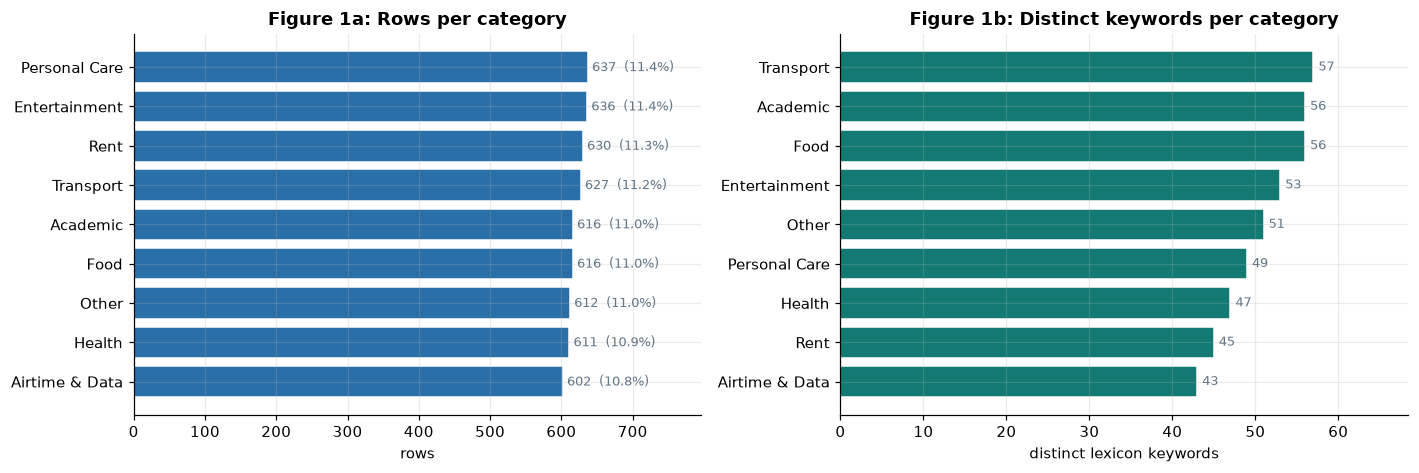

Class balance: max/min row ratio = 1.06  (1.00 would be perfectly even)
Keyword coverage: 43 (Airtime & Data) to 57 (Transport) keywords per category
Rows per keyword: 11.0 to 14.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

counts = df.category.value_counts().sort_values()
axes[0].barh(counts.index, counts.values, color=BLUE, edgecolor="white")
axes[0].set_title("Figure 1a: Rows per category")
axes[0].set_xlabel("rows")
for i, v in enumerate(counts.values):
    axes[0].text(v + 6, i, f"{v}  ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5, color=GREY)
axes[0].set_xlim(0, counts.max() * 1.25)

kws = kw_stats.keywords.sort_values()
axes[1].barh(kws.index, kws.values, color=TEAL, edgecolor="white")
axes[1].set_title("Figure 1b: Distinct keywords per category")
axes[1].set_xlabel("distinct lexicon keywords")
for i, v in enumerate(kws.values):
    axes[1].text(v + 0.6, i, str(v), va="center", fontsize=8.5, color=GREY)
axes[1].set_xlim(0, kws.max() * 1.2)

plt.tight_layout(); plt.show()

spread = counts.max() / counts.min()
print(f"Class balance: max/min row ratio = {spread:.2f}  (1.00 would be perfectly even)")
print(f"Keyword coverage: {kws.min()} ({kws.idxmin()}) to {kws.max()} ({kws.idxmax()}) keywords per category")
print(f"Rows per keyword: {kw_stats.rows_per_keyword.min():.1f} to {kw_stats.rows_per_keyword.max():.1f}")

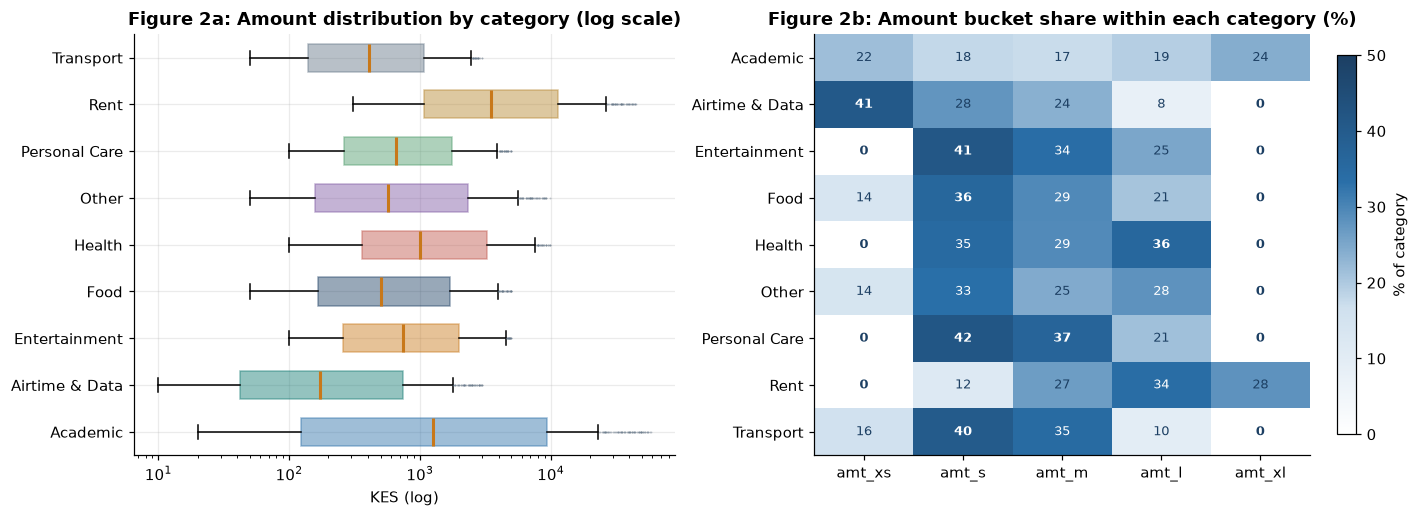

Median amount by category (KES):
category
Airtime & Data     172.5
Transport          411.0
Food               503.0
Other              567.0
Personal Care      662.0
Entertainment      748.5
Health            1000.0
Academic          1255.5
Rent              3468.5

Categories that ever produce an amt_xl (>= KES 10,000) transaction:
  Academic (24.0%), Rent (27.9%)
Categories that never do: Airtime & Data, Entertainment, Food, Health, Other, Personal Care, Transport

Share of the amt_xs (< KES 100) rows held by each category:
  Airtime & Data 37.9%, Academic 20.6%, Transport 15.1%, Other 13.3%, Food 13.1%
Categories with no amt_xs rows at all: Entertainment, Health, Personal Care, Rent


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

cats = sorted(df.category.unique())
data = [df.loc[df.category == c, "amount"].values for c in cats]
bp = hboxplot(axes[0], data, cats, patch_artist=True, widths=0.6,
              flierprops=dict(marker=".", markersize=2.5, alpha=0.35, markerfacecolor=GREY,
                              markeredgecolor="none"),
              medianprops=dict(color=AMBER, linewidth=2))
for patch, colour in zip(bp["boxes"], PALETTE):
    patch.set_facecolor(colour); patch.set_alpha(0.45); patch.set_edgecolor(colour)
axes[0].set_xscale("log")
axes[0].set_title("Figure 2a: Amount distribution by category (log scale)")
axes[0].set_xlabel("KES (log)")

pivot = (pd.crosstab(df.category, df.bucket, normalize="index")
           .reindex(columns=ORDER).fillna(0) * 100)
im = axes[1].imshow(pivot.values, cmap=HEAT, aspect="auto", vmin=0, vmax=50)
axes[1].set_xticks(range(len(ORDER))); axes[1].set_xticklabels(ORDER)
axes[1].set_yticks(range(len(pivot))); axes[1].set_yticklabels(pivot.index)
axes[1].set_title("Figure 2b: Amount bucket share within each category (%)")
axes[1].grid(False)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                     color="white" if v > 28 else NAVY,
                     fontweight="bold" if v == 0 or v > 35 else "normal")
plt.colorbar(im, ax=axes[1], fraction=0.035, label="% of category")
plt.tight_layout(); plt.show()

print("Median amount by category (KES):")
print(df.groupby("category").amount.median().sort_values().to_string())
print("\nCategories that ever produce an amt_xl (>= KES 10,000) transaction:")
xl = pivot["amt_xl"]
print("  " + ", ".join(f"{c} ({v:.1f}%)" for c, v in xl[xl > 0].items()) or "  none")
print("Categories that never do:", ", ".join(xl[xl == 0].index))
# Who makes the smallest payments: share of all amt_xs rows held by each category
xs = df.loc[df.bucket == "amt_xs", "category"].value_counts(normalize=True).mul(100).round(1)
print("\nShare of the amt_xs (< KES 100) rows held by each category:")
print("  " + ", ".join(f"{c} {v}%" for c, v in xs.items()))
print("Categories with no amt_xs rows at all:", ", ".join(c for c in cats if c not in xs.index))

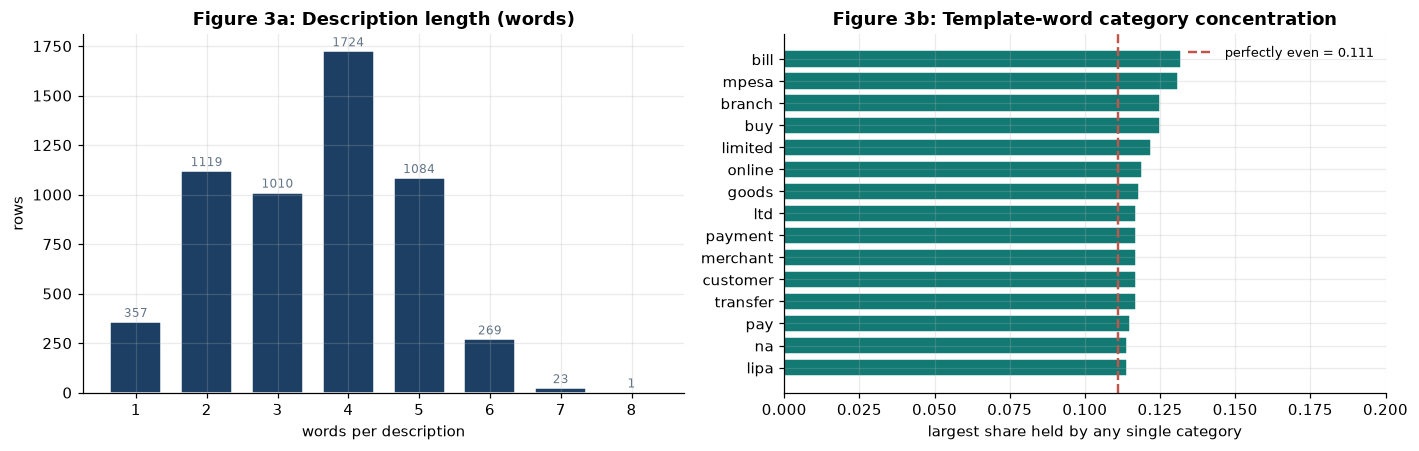

Vocabulary: 510 single words, 5,354 features with word pairs included
Description length: mean 3.53 words, median 4, range 1-8
Rows: 5,587  |  Features: 5,354  |  ratio = 1.04 rows per feature


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

lengths = df.n_tokens.value_counts().sort_index()
axes[0].bar(lengths.index, lengths.values, color=NAVY, edgecolor="white", width=0.72)
axes[0].set_title("Figure 3a: Description length (words)")
axes[0].set_xlabel("words per description"); axes[0].set_ylabel("rows")
for x, v in lengths.items():
    axes[0].text(x, v + 25, str(v), ha="center", fontsize=8, color=GREY)

nb_ = neutrality.sort_values("max_category_share")
axes[1].barh(nb_.token, nb_.max_category_share, color=TEAL, edgecolor="white")
axes[1].axvline(UNIFORM, color=RED, linestyle="--", linewidth=1.6,
                label=f"perfectly even = {UNIFORM:.3f}")
axes[1].set_title("Figure 3b: Template-word category concentration")
axes[1].set_xlabel("largest share held by any single category")
axes[1].legend(fontsize=8.5, frameon=False)
axes[1].set_xlim(0, max(0.2, nb_.max_category_share.max() * 1.25))

plt.tight_layout(); plt.show()

from sklearn.feature_extraction.text import CountVectorizer
# Same settings as the model will use, so these counts are the real feature counts
vec_probe = CountVectorizer(**vectorizer_kwargs()); vec_probe.fit(df.doc)
uni_probe = CountVectorizer(lowercase=False, token_pattern=r"\S+"); uni_probe.fit(df.doc)
print(f"Vocabulary: {len(uni_probe.get_feature_names_out()):,} single words, "
      f"{len(vec_probe.get_feature_names_out()):,} features with word pairs included")
print(f"Description length: mean {df.n_tokens.mean():.2f} words, median {df.n_tokens.median():.0f}, "
      f"range {df.n_tokens.min()}-{df.n_tokens.max()}")
print(f"Rows: {len(df):,}  |  Features: {len(vec_probe.get_feature_names_out()):,}  "
      f"|  ratio = {len(df)/len(vec_probe.get_feature_names_out()):.2f} rows per feature")

## Observations from the EDA

### Observation 1: the classes are balanced, but only because we made them so

Every category holds about 11% of the rows, and the largest has only 1.06 times as many as the smallest
(Figure 1a). That comes from `ROWS_PER_CATEGORY = 600` in the generator, not from real spending.

It means plain accuracy is a fair measure for this data, and random guessing would score about 11%. Real
statements will be less even, so the class priors will need updating once real data exists.

### Observation 2: the real imbalance is in the number of merchants

Row counts are level, but the number of distinct keywords behind them is not: from 43 for Airtime & Data
to 57 for Transport (Figure 1b). The generator makes up for it by writing more rows per keyword for the
thinner categories (11 to 14).

So a category with fewer keywords has a narrower vocabulary and will struggle more with merchants it has
never seen, even though its row count looks healthy.

### Observation 3: the amount helps mainly at the extremes

Only Academic and Rent ever reach `amt_xl` (KES 10,000 and above). At the other end, Airtime & Data holds
the largest share of the `amt_xs` rows (37.9%), while Entertainment, Health, Personal Care and Rent never
go below KES 100 at all (Figure 2b). In the crowded KES 100 to 2,000 middle, most categories overlap.

So the amount token is worth keeping, but it mostly helps for very large or very small amounts. Because
the ranges were set by hand, this is partly our own assumption about prices showing through.

### Observation 4: descriptions are very short

The mean description is 3.53 words (median 4, longest 8), and template words such as "pay bill to" take
up most of that (Figure 3a). The useful signal is often a single word: the merchant name.

That suits a model that treats each word as separate evidence, which is exactly what Naive Bayes assumes.
It also means that if the model does not know the merchant word, it has very little else to go on.

### Observation 5: the template words carry no category signal

No template word puts more than 0.132 of its rows in any one category, against 0.111 for a perfectly
even spread (Figure 3b).

So the generator works as designed. The model cannot score well by learning the sentence templates; any
accuracy has to come from the merchant words and the amount token.

### Observation 6: there are as many features as rows

With word pairs included there are 5,354 features for 5,587 rows, so roughly one row per feature. Most
of the matrix is empty.

This is the situation where models usually over-fit, which is another reason to prefer a simple model
like Naive Bayes. It also suggests a single decision tree will over-fit here, and in Part E it does: it
scores 100% on its training folds but clearly less on the test folds.

---
# Part D: The base model
*CRISP-DM phases: modelling, then evaluation*

The base model is a two-step pipeline:

```
doc  →  CountVectorizer (single words + word pairs)  →  MultinomialNB  →  category
```

`CountVectorizer` turns each document into word counts. Naive Bayes is used with its default smoothing
(alpha = 1), which stops a word that never appeared with a category in training from ruling that category
out completely.

The model is evaluated with **k-fold cross validation**. The data is split into 5 folds; the model is
trained on 4 and tested on the fifth, and this is repeated until every fold has been the test fold once.
The folds are stratified (each keeps the same mix of categories) and shuffled with a fixed seed, so every
model in this notebook is tested on exactly the same splits.

The metric is **accuracy**, the share of rows given the right category. The classes are near-balanced
(about 11% each), so accuracy is appropriate here. Random guessing across nine equal classes would be
about 11% accurate, which is the reference point.

In [14]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, cross_validate
from sklearn.metrics import confusion_matrix, precision_score, recall_score

X, y = df.doc, df.category
CLASSES = sorted(y.unique())
# One fixed set of 5 folds, reused by every model so the comparison is fair
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_pipeline(clf):
    # lowercase=False and token_pattern=r"\S+" (inside vectorizer_kwargs): the text is already cleaned,
    # and sklearn's default pattern would drop one-letter words that the app's TypeScript code keeps
    return Pipeline([("vec", CountVectorizer(**vectorizer_kwargs())), ("clf", clf)])

base_model = make_pipeline(MultinomialNB())
scores = cross_val_score(base_model, X, y, cv=SKF, scoring="accuracy")

print(f"{len(X):,} documents, {len(CLASSES)} classes")
print("Accuracy on each fold:", ", ".join(f"{s:.4f}" for s in scores))
print(f"Base model accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")
print(f"Random guessing:     {1/len(CLASSES):.4f}")

5,587 documents, 9 classes
Accuracy on each fold: 0.9776, 0.9741, 0.9696, 0.9731, 0.9785
Base model accuracy: 0.9746 (+/- 0.0032)
Random guessing:     0.1111


### A limitation of this score

Our training rows were generated from 457 merchant keywords, so several rows describe the same merchant.
A standard k-fold split can therefore place the same merchant in both the training and testing folds,
which means the score above is likely optimistic: the model may be recognising merchants it has already
seen rather than generalising to new ones. This is a form of overfitting to the training merchants.
Testing on real M-Pesa statements would give a more realistic figure.

## Precision, recall and the confusion matrix

Accuracy is one number for all nine classes. Per-class **precision** (of the rows predicted as a
category, how many really were) and **recall** (of the rows that really were a category, how many were
found) show where the errors are. The predictions below are out-of-fold: each row is predicted by the
model that did not see it in training, using the same 5 folds.

,precision,recall,rows
Academic,0.9983,0.9302,616
Airtime & Data,0.9625,0.9817,602
Entertainment,0.9517,0.9906,636
Food,0.9916,0.9627,616
Health,0.9711,0.9902,611
Other,0.9866,0.9657,612
Personal Care,0.9678,0.9922,637
Rent,0.9627,0.9841,630
Transport,0.9839,0.9729,627


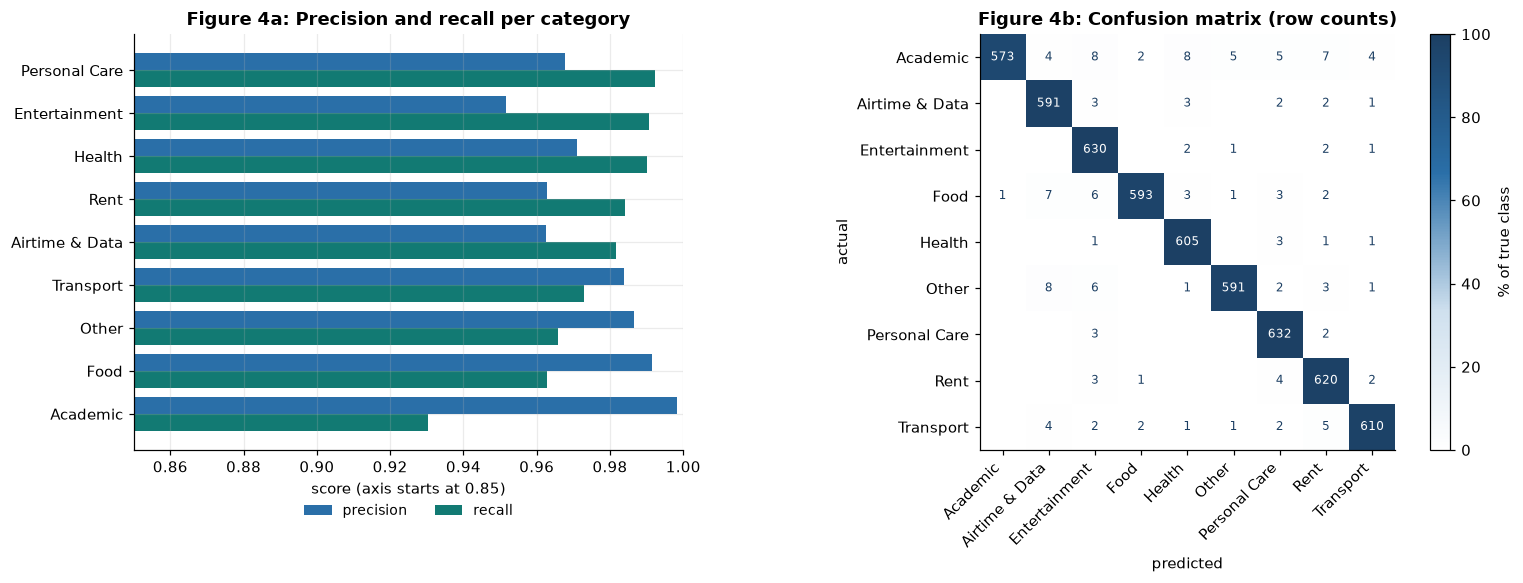

Most common mistakes (actual -> predicted: rows):
  Academic        -> Entertainment   8
  Academic        -> Health          8
  Other           -> Airtime & Data  8
  Academic        -> Rent            7
  Food            -> Airtime & Data  7

Rows misclassified: 142 of 5,587
Highest recall:    Personal Care (0.9922)
Lowest recall:     Academic (0.9302)
Lowest precision:  Entertainment (0.9517)
Accuracy of these out-of-fold predictions: 0.9746


In [15]:
# Each row is predicted by the fold model that was not trained on it
pred = cross_val_predict(base_model, X, y, cv=SKF)

per_class = pd.DataFrame({
    "precision": precision_score(y, pred, labels=CLASSES, average=None),
    "recall":    recall_score(y, pred, labels=CLASSES, average=None),
    "rows":      y.value_counts().reindex(CLASSES).values,
}, index=CLASSES).round(4)
display(per_class)
cm = confusion_matrix(y, pred, labels=CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1, 1.25]})

o = per_class.sort_values("recall")
ypos = np.arange(len(o))
axes[0].barh(ypos + 0.2, o.precision, height=0.4, color=BLUE, label="precision")
axes[0].barh(ypos - 0.2, o.recall, height=0.4, color=TEAL, label="recall")
axes[0].set_yticks(ypos); axes[0].set_yticklabels(o.index)
# Start the axis just below the lowest score so the differences between classes are visible
low = max(0.0, np.floor(min(o.precision.min(), o.recall.min()) * 20) / 20 - 0.05)
axes[0].set_xlim(low, 1.0)
axes[0].set_xlabel(f"score (axis starts at {low:.2f})")
axes[0].set_title("Figure 4a: Precision and recall per category")
axes[0].legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)

cmn = cm / cm.sum(axis=1, keepdims=True) * 100
im = axes[1].imshow(cmn, cmap=HEAT, vmin=0, vmax=100)
axes[1].set_xticks(range(len(CLASSES)))
axes[1].set_xticklabels(CLASSES, rotation=45, ha="right")
axes[1].set_yticks(range(len(CLASSES))); axes[1].set_yticklabels(CLASSES)
axes[1].set_title("Figure 4b: Confusion matrix (row counts)")
axes[1].set_xlabel("predicted"); axes[1].set_ylabel("actual"); axes[1].grid(False)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j]:
            axes[1].text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8,
                         color="white" if cmn[i, j] > 50 else NAVY)
plt.colorbar(im, ax=axes[1], fraction=0.04, label="% of true class")
plt.tight_layout(); plt.show()

# Off-diagonal cells are the mistakes; list the largest ones
mistakes = (pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
              .where(~np.eye(len(CLASSES), dtype=bool)).stack().dropna().astype(int)
              .sort_values(ascending=False))
print("Most common mistakes (actual -> predicted: rows):")
for (actual, predicted), n in mistakes.head(5).items():
    print(f"  {actual:<15} -> {predicted:<15} {n}")
print(f"\nRows misclassified: {int(cm.sum() - np.trace(cm))} of {int(cm.sum()):,}")
print(f"Highest recall:    {per_class.recall.idxmax()} ({per_class.recall.max():.4f})")
print(f"Lowest recall:     {per_class.recall.idxmin()} ({per_class.recall.min():.4f})")
print(f"Lowest precision:  {per_class.precision.idxmin()} ({per_class.precision.min():.4f})")
print(f"Accuracy of these out-of-fold predictions: {(pred == y).mean():.4f}")

### Reading the base model's results

The base model gets 97.46% of rows right: 142 of the 5,587 rows are misclassified. Recall is highest
for Personal Care (0.9922) and lowest for Academic (0.9302). Academic loses rows to several categories at
once, most often Entertainment and Health (8 rows each) and Rent (7). A likely reason is Observation 3:
Academic covers everything from KES 20 printing to KES 60,000 fees, so its amount token overlaps with
almost every other category. The next most common mistakes, Other and Food predicted as Airtime & Data
(8 and 7 rows), both involve small payments, the range where Airtime & Data is most common.

Precision is lowest for Entertainment (0.9517). It is the category that most often receives other
categories' rows, which shows in its column of Figure 4b.

These are strong numbers, but the limitation above applies: most test rows are merchants the model has
already seen in training.

---
# Part E: Comparison models
*CRISP-DM phase: evaluation*

The brief asks for further validation through comparison models built with the same process. The five
models below come from the course's ML cheat sheet and the Theories of Machine Learning lecture, and each
goes through the identical pipeline: the same documents, the same `CountVectorizer`, the same 5 folds and
the same accuracy metric. Any difference is then down to the algorithm.

Alongside test accuracy, the table shows accuracy on the training folds. A model that scores much higher
on the data it trained on than on the held-out fold is **overfitting**; a model that scores low on both
is **underfitting**.

In [16]:
models = {
    "Multinomial Naive Bayes (base)": MultinomialNB(),
    "Logistic Regression":            LogisticRegression(max_iter=1000),
    "Decision Tree":                  DecisionTreeClassifier(random_state=42),
    "K-Nearest Neighbours":           KNeighborsClassifier(),
    "Random Forest":                  RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting":              GradientBoostingClassifier(random_state=42),
}

rows = []
for name, clf in models.items():
    # return_train_score=True also scores each model on its own training folds, to spot overfitting
    r = cross_validate(make_pipeline(clf), X, y, cv=SKF, scoring="accuracy",
                       return_train_score=True, n_jobs=-1)
    rows.append({"Model": name, "test_accuracy": r["test_score"].mean(), "std": r["test_score"].std(),
                 "train_accuracy": r["train_score"].mean()})
    print(f"  {name:<32} test {r['test_score'].mean():.4f}   train {r['train_score'].mean():.4f}")

comparison = (pd.DataFrame(rows)
                .assign(train_minus_test=lambda t: t.train_accuracy - t.test_accuracy)
                .sort_values("test_accuracy", ascending=False).round(4).reset_index(drop=True))
BASE_SCORE = comparison.loc[comparison.Model.str.contains("base"), "test_accuracy"].iloc[0]
print()
display(comparison)

  Multinomial Naive Bayes (base)   test 0.9746   train 0.9968


  Logistic Regression              test 0.9998   train 1.0000


  Decision Tree                    test 0.9042   train 1.0000


  K-Nearest Neighbours             test 0.2577   train 0.5495


  Random Forest                    test 0.9535   train 1.0000


  Gradient Boosting                test 0.9993   train 0.9996



,Model,test_accuracy,std,train_accuracy,train_minus_test
0,Logistic Regression,0.9998,0.0004,1.0000,0.0002
1,Gradient Boosting,0.9993,0.0009,0.9996,0.0003
2,Multinomial Naive Bayes (base),0.9746,0.0032,0.9968,0.0222
3,Random Forest,0.9535,0.0067,1.0000,0.0465
4,Decision Tree,0.9042,0.0109,1.0000,0.0958
5,K-Nearest Neighbours,0.2577,0.0163,0.5495,0.2918


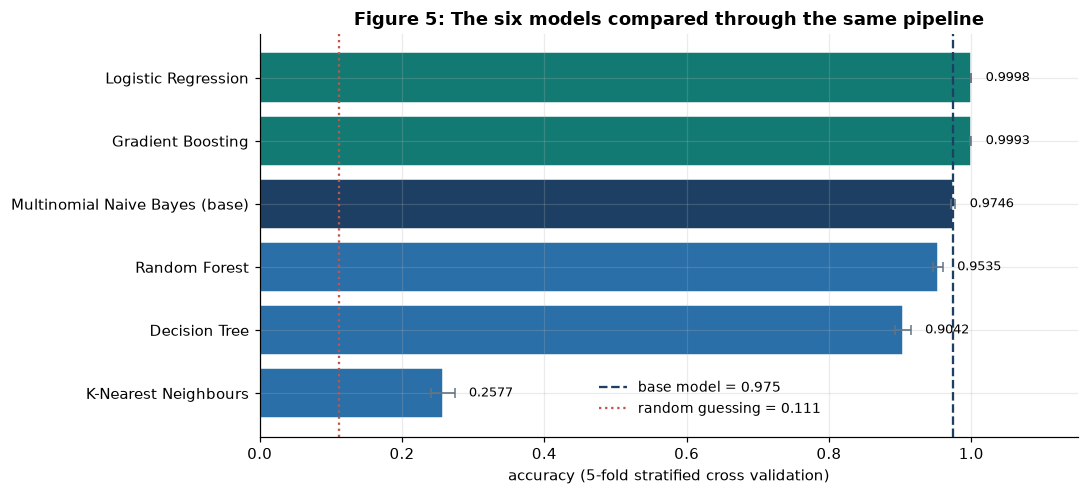

Best performer : Logistic Regression  (0.9998)
Base model     : 0.9746
Difference     : +0.0252 accuracy


In [17]:
fig, ax = plt.subplots(figsize=(10, 4.6))
c = comparison.sort_values("test_accuracy")
colours = [NAVY if "base" in m else TEAL if s > BASE_SCORE else BLUE
           for m, s in zip(c.Model, c.test_accuracy)]
bars = ax.barh(c.Model, c.test_accuracy, xerr=c["std"], color=colours, edgecolor="white",
               error_kw=dict(ecolor=GREY, lw=1.1, capsize=3))
ax.axvline(BASE_SCORE, color=NAVY, linestyle="--", linewidth=1.5,
           label=f"base model = {BASE_SCORE:.3f}")
ax.axvline(1/len(CLASSES), color=RED, linestyle=":", linewidth=1.5,
           label=f"random guessing = {1/len(CLASSES):.3f}")
ax.set_xlabel("accuracy (5-fold stratified cross validation)")
ax.set_title("Figure 5: The six models compared through the same pipeline")
# Legend sits in the empty space beside the shortest bar, clear of the base-model line
ax.legend(frameon=False, fontsize=9, loc="lower left", bbox_to_anchor=(0.4, 0.02))
for b, v, sd in zip(bars, c.test_accuracy, c["std"]):
    ax.text(v + sd + 0.02, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontsize=8.5)
ax.set_xlim(0, 1.15)
plt.tight_layout(); plt.show()

best = comparison.iloc[0]
print(f"Best performer : {best.Model}  ({best.test_accuracy:.4f})")
print(f"Base model     : {BASE_SCORE:.4f}")
print(f"Difference     : {best.test_accuracy - BASE_SCORE:+.4f} accuracy")

### Why K-Nearest Neighbours does so badly

KNN labels a row by the categories of the 5 training rows closest to it. With word counts, "closest"
means "shares the most words", and most of the words in a description are template words, not the
merchant. The check below looks at what each row has in common with its 5 nearest neighbours.

In [18]:
from sklearn.neighbors import NearestNeighbors

# Distances are measured on the same word-count vectors the KNN model uses
count_matrix = CountVectorizer(**vectorizer_kwargs()).fit_transform(X)
_, idx = NearestNeighbors(n_neighbors=6).fit(count_matrix).kneighbors(count_matrix)
neighbours = idx[:, 1:]   # column 0 is the row itself

# A row's template is its description with the merchant keyword blanked out
template = np.asarray([d.replace(k, "{kw}") for d, k in zip(df.description, df.keyword)], dtype=object)
for label, values in [("same template", template),
                      ("same merchant keyword", df.keyword.to_numpy(dtype=object)),
                      ("same category", df.category.to_numpy(dtype=object))]:
    print(f"Neighbours with the {label:<22} {(values[neighbours] == values[:, None]).mean():.1%}")

Neighbours with the same template          92.3%
Neighbours with the same merchant keyword  7.2%
Neighbours with the same category          23.8%


## What the comparison shows

- Logistic Regression is the most accurate model (0.9998), with Gradient Boosting close behind (0.9993).
  Both beat the Naive Bayes base model (0.9746) by about 2.5 percentage points.
- The Decision Tree overfits, as Observation 6 predicted: 100% on its training folds but 0.9042 on the
  test folds. Random Forest averages 200 trees and halves that gap (0.9535 on the test folds), but it
  still trails Naive Bayes.
- K-Nearest Neighbours underfits badly: 0.5495 even on its own training folds and 0.2577 on the test
  folds, only about 2.3 times random guessing. The check above shows why. 92.3% of each row's nearest
  neighbours share its template, but only 7.2% share its merchant, so "nearest" here means "same sentence
  pattern", which says almost nothing about the category.
- Naive Bayes has only a small gap between training and test accuracy (0.9968 against 0.9746), so it is
  not badly overfitting.

The top three models all score close to 100%, and that should not be taken at face value. As the
limitation note in Part D explains, the same merchants appear in both the training and the test folds,
so a model that simply remembers merchant names can score almost perfectly. Logistic Regression's
near-perfect score is probably mostly that.

## Regularisation

The notes describe regularisation as a way to handle overfitting: it adds a penalty that keeps the
model's weights small, which simplifies the model. Lasso (L1) and ridge (L2) are the two standard
penalties, and scikit-learn's Logistic Regression uses ridge by default. Its strength is set by `C`: a
small `C` means strong regularisation and a simpler model, a large `C` means weak regularisation.

Naive Bayes has no penalty of this kind, so the sweep below uses Logistic Regression, through the same
pipeline and folds.

,C,regularisation,train_accuracy,test_accuracy
0,0.01,strong,0.5855,0.5158
1,0.10,strong,0.9858,0.9465
2,1.00,default,1.0000,0.9998
3,10.00,weak,1.0000,1.0000
4,100.00,weak,1.0000,1.0000


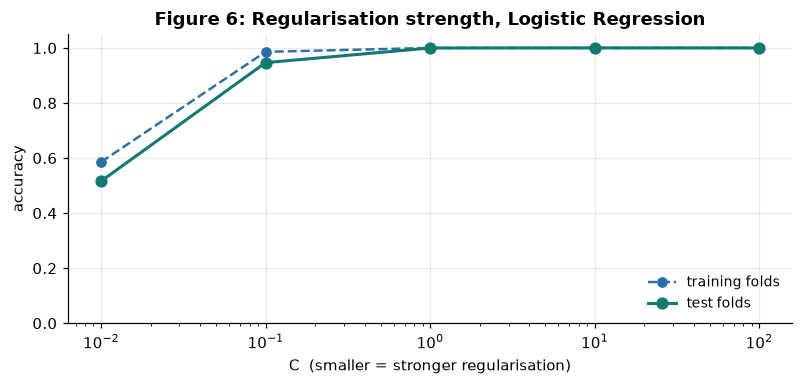

Strongest regularisation (C = 0.01): train 0.5855, test 0.5158
Best test accuracy: 1.0000 at C = 10.0


In [19]:
sweep = []
for C in [0.01, 0.1, 1.0, 10.0, 100.0]:
    # Smaller C = bigger penalty on the weights = stronger regularisation
    r = cross_validate(make_pipeline(LogisticRegression(max_iter=1000, C=C)), X, y, cv=SKF,
                       scoring="accuracy", return_train_score=True, n_jobs=-1)
    sweep.append({"C": C, "regularisation": "strong" if C < 1 else "weak" if C > 1 else "default",
                  "train_accuracy": r["train_score"].mean(), "test_accuracy": r["test_score"].mean()})
sweep_df = pd.DataFrame(sweep).round(4)
display(sweep_df)

fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.plot(sweep_df.C, sweep_df.train_accuracy, "o--", color=BLUE, linewidth=1.6, markersize=6,
        label="training folds")
ax.plot(sweep_df.C, sweep_df.test_accuracy, "o-", color=TEAL, linewidth=2, markersize=7,
        label="test folds")
ax.set_xscale("log"); ax.set_xlabel("C  (smaller = stronger regularisation)")
ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.05)
ax.set_title("Figure 6: Regularisation strength, Logistic Regression")
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout(); plt.show()

strongest, best_row = sweep_df.iloc[0], sweep_df.loc[sweep_df.test_accuracy.idxmax()]
print(f"Strongest regularisation (C = {strongest.C}): train {strongest.train_accuracy:.4f}, "
      f"test {strongest.test_accuracy:.4f}")
print(f"Best test accuracy: {best_row.test_accuracy:.4f} at C = {best_row.C}")

With strong regularisation (C = 0.01) Logistic Regression underfits: 0.5855 on its own training folds
and 0.5158 on the test folds. The penalty is so heavy that the model cannot give enough weight to the
merchant words. Weakening it helps up to the default C = 1, and from C = 10 upwards both training and
test accuracy reach 1.0000.

So on this data, less regularisation scores higher. That is the opposite of what we would expect from a
model with as many features as rows (Observation 6), and it is another sign of the limitation in Part D.
When the test folds contain the same merchants as the training folds, memorising them is rewarded rather
than punished, so the penalty against overfitting only gets in the way. On real statements with unseen
merchants a stronger penalty could well do better, which the real test set should check.

---
# Part F: Conclusions
*CRISP-DM phases: evaluation and deployment*

- Approach: supervised, multi-class text classification of M-Pesa descriptions into nine categories.
- Base model: `CountVectorizer` (words and word pairs) with Multinomial Naive Bayes at default smoothing.
  It scores 0.9746 accuracy in 5-fold stratified cross validation, against about 0.11 for random guessing.
- Comparison: of the six taught models, Logistic Regression (0.9998) and Gradient Boosting (0.9993) score
  highest. The Decision Tree and Random Forest overfit, and K-Nearest Neighbours underfits because its
  distances are dominated by template words.
- Regularisation: strong regularisation makes Logistic Regression underfit, and weaker regularisation
  scores higher on this data.

The main caveat is the limitation from Part D. The 5,587 training rows come from only 457 merchant
keywords, so the same merchant usually appears in both the training and the test folds, and the models
are partly being tested on merchants they have already seen. That is a form of overfitting to the
training merchants, and it makes every score here likely optimistic; the near-100% scores of the best
models are probably mostly that. Testing on real M-Pesa statements would give a more realistic figure.

Naive Bayes stays as the shipped model for now. Logistic Regression scores higher and would also be
simple to run in TypeScript (one weight per word per class, plus a bias), but its lead is small and may
come from memorising merchants. The comparison should be repeated on real data before switching.

## Deployment

The deployment phase is the export. `scripts/train.py` trains the model and `scripts/export.py` writes it
to `out/model.json` (class priors, word log-probabilities and the vocabulary), which the app's TypeScript
server loads directly. `scripts/predict.py` runs the same file from Python for testing.
`scripts/train.py` builds the shipped model exactly as Part D does (same pipeline, default smoothing,
same 5 folds), and the accuracy it records in `out/metrics.json` matches the 0.9746 above.

## Next steps

1. Produce `data/test_real.csv`: run `extract.py` on real statements and hand-label a few hundred rows.
   Without it there is no realistic accuracy figure.
2. Re-run this comparison on the real test set, to see whether Logistic Regression's lead holds.
3. Add more merchants to `lexicon.json`, especially in the thinner categories (Observation 2).
4. Add a confidence threshold, so low-confidence predictions go to the user to confirm.
5. Update the class priors once real data shows how spending is actually split (Observation 1).

## Reproducing this notebook

From the repository root:

```bash
python -m venv .venv
.venv/Scripts/activate              # macOS/Linux: source .venv/bin/activate
pip install -r requirements.txt
python scripts/generate.py          # lexicon.json -> data/train.csv
jupyter notebook notebooks/NaiveBayes_Base.ipynb
```